# Comment note-t-on un film ? Exploitation de la base de données MovieLens 32M

## Introduction et problématique

MovieLens est un service de recommandation de films géré par GroupLens Research (Université du Minnesota). Les utilisateurs y notent les films qu'ils ont vus, de 0,5 à 5 étoiles, pour recevoir des recommandations. Nous utilisons la version MovieLens 32M, publiée en octobre 2023 : 32 millions de notes, données par 200 948 utilisateurs sur 87 585 films, entre janvier 1995 et octobre 2023.
Une note semble être une mesure simple de la qualité d'un film. En pratique, elle dépend aussi de celui qui note (indulgent ou sévère, débutant ou habitué de la plateforme), du film (genre, époque de sortie) et du moment où la note est donnée. De plus, les utilisateurs ne notent pas des films tirés au hasard : ils notent ceux qu'ils ont choisi de voir, souvent des films qu'ils pensaient aimer.

### Problématique
Que mesure réellement une note sur MovieLens ? Parmi les écarts de notes observés, que doit-on attribuer au film (genre, ancienneté), que doit-on attribuer à l'utilisateur (indulgence, ancienneté sur la plateforme), et que doit-on attribuer à la façon dont les notes sont produites et sélectionnées ?

### Démarche
Après avoir téléchargé et joint les données (parties I et II), puis les avoir décrites (partie III), nous étudions deux dimensions de l'évolution des notes dans le temps : l'ancienneté de l'utilisateur sur la plateforme (partie IV-A), puis l'ancienneté du film au moment de la notation (partie IV-B). 

(?) Pour chacune, nous distinguons un effet de composition (qui note, quels films sont notés) d'un effet de comportement (une même personne, un même film, qui note différemment). Les données sont observationnelles : nous décrivons des associations, pas des causes.

# I - MovieLens 32M : téléchargement et aperçu des données

In [1]:
from donnees import telecharger, extraire
import os
import zipfile

import requests
import pandas as pd

URL = "https://files.grouplens.org/datasets/movielens/ml-32m.zip"
NOM_ZIP = "ml-32m.zip"
DOSSIER = "data"

In [2]:
telecharger(URL, NOM_ZIP)
extraire(NOM_ZIP, DOSSIER)

Le ZIP existe déjà, pas de nouveau téléchargement.
Contenu du ZIP : ['ml-32m/', 'ml-32m/tags.csv', 'ml-32m/links.csv', 'ml-32m/README.txt', 'ml-32m/checksums.txt', 'ml-32m/ratings.csv', 'ml-32m/movies.csv']


In [3]:
chemin = os.path.join(DOSSIER, "ml-32m")

movies = pd.read_csv(os.path.join(chemin, "movies.csv"))
tags = pd.read_csv(os.path.join(chemin, "tags.csv"))
links = pd.read_csv(os.path.join(chemin, "links.csv"))
ratings = pd.read_csv(os.path.join(chemin, "ratings.csv"))

In [ ]:
# Pour un téléchargement en local

import os

import pandas as pd

DOSSIER_CSV = "ml-32m"


movies = pd.read_csv(os.path.join(DOSSIER_CSV, "movies.csv"))
tags = pd.read_csv(os.path.join(DOSSIER_CSV, "tags.csv"))
links = pd.read_csv(os.path.join(DOSSIER_CSV, "links.csv"))
ratings = pd.read_csv(os.path.join(DOSSIER_CSV, "ratings.csv"))

display(movies.head())
display(ratings.shape)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


(32000204, 4)

On affiche le premier dataframe, qui comporte une clé d'identification des films (movieId), le titre ainsi que leur année, et le genre associé. 
La base de données comporte 87585 films.

In [5]:
print(movies.shape)
movies.head()

(87585, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


On affiche aussi les notes de ces films, qui vont être notre base de donnée principale. Le fichier est particulièrement volumineux (32 millions de notes). L'userId permet de voir quel utilisateur a mis quelle note, ce qui sera utile. 

In [6]:
print(ratings.shape)
ratings.head()

(32000204, 4)


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


La base de données donne aussi accès à des tags, c'est-à-dire des mots que les utilisateurs ont associé aux films. Nous choisissons de ne pas les étudier dans le cadre de ce projet.

In [7]:
print(tags.shape)
tags.head()

(2000072, 4)


,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469
3,34,2174,music,1249808064
4,34,2174,weird,1249808102


Ce dataframe permet de faire des jointures avec des bases de données extérieures, en donnant la clé correspondante pour les films dans cette base et dans les bases IMDB et TMDB.

In [8]:
print(links.shape)
links.head()

(87585, 3)


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


# II- Création de dataframes utilisables pour l'analyse

On peut d'abord séparer l'année et le titre du film dans le dataframe movies.

In [9]:
movies_with_date = movies.copy()

# 1. on récupère l'année (4 chiffres entre parenthèses, à la fin du titre)
movies_with_date["year"] = movies_with_date["title"].str.extract(r"\((\d{4})\)\s*$", expand=False)

# 2. on enlève l'année du titre
movies_with_date["title"] = movies_with_date["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)

# 3. on convertit l'année en nombre
movies_with_date["year"] = pd.to_numeric(movies_with_date["year"])

movies_with_date

,movieId,title,genres,year
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995.0
1,2,Jumanji,Adventure|Children|Fantasy,1995.0
2,3,Grumpier Old Men,Comedy|Romance,1995.0
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995.0
4,5,Father of the Bride Part II,Comedy,1995.0
...,...,...,...,...
87580,292731,The Monroy Affaire,Drama,2022.0
87581,292737,Shelter in Solitude,Comedy|Drama,2023.0
87582,292753,Orca,Drama,2023.0
87583,292755,The Angry Breed,Drama,1968.0


Certains films n'ont pas de date, 617 sur 87 585 : 

In [10]:
movies_with_date[movies_with_date["year"].isna()]

,movieId,title,genres,year
15038,79607,"Millions Game, The (Das Millionenspiel)",Action|Drama|Sci-Fi|Thriller,NaN
18796,98063,Mona and the Time of Burning Love (Mona ja pal...,Drama,NaN
25425,123619,Terrible Joe Moran,(no genres listed),NaN
26356,125571,The Court-Martial of Jackie Robinson,(no genres listed),NaN
26381,125632,In Our Garden,(no genres listed),NaN
...,...,...,...,...
86528,288927,Fortunes,Comedy,NaN
86634,289193,The Wonderful Story of Henry Sugar,Adventure|Children|Comedy,NaN
86833,289909,Rattler,(no genres listed),NaN
87074,290775,Being Romanian: A Family Journal,(no genres listed),NaN


On exclut les films sans années, et on vérifie qu'elles ont bien été exclues. On réindexe bien les lignes aussi, sinon il y a un écart de 617 entre le nombre de lignes et le plus grand index. On peut aussi transformer les flottants en entiers maintenant qu'il n'y a plus de Na dans la colonne year.

In [11]:
movies_with_date = movies_with_date.dropna(subset=["year"]).reset_index(drop=True)
movies_with_date["year"].isna().sum()
movies_with_date["year"] = movies_with_date["year"].astype(int)


In [12]:
movies_with_date

,movieId,title,genres,year
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995
1,2,Jumanji,Adventure|Children|Fantasy,1995
2,3,Grumpier Old Men,Comedy|Romance,1995
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995
4,5,Father of the Bride Part II,Comedy,1995
...,...,...,...,...
86963,292731,The Monroy Affaire,Drama,2022
86964,292737,Shelter in Solitude,Comedy|Drama,2023
86965,292753,Orca,Drama,2023
86966,292755,The Angry Breed,Drama,1968


On peut aussi faire une jointure des notes et des films pour avoir le nom du film à côté de sa note. 
On commence par rajouter une colonne qui convertit le timestamp en heure lisible. Dans MovieLens, timestamp est un nombre de secondes écoulées depuis le 1er janvier 1970 (temps Unix).

In [13]:
ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings.head()

,userId,movieId,rating,timestamp,date
0,1,17,4.0,944249077,1999-12-03 19:24:37
1,1,25,1.0,944250228,1999-12-03 19:43:48
2,1,29,2.0,943230976,1999-11-22 00:36:16
3,1,30,5.0,944249077,1999-12-03 19:24:37
4,1,32,5.0,943228858,1999-11-22 00:00:58


In [14]:
ratings_movies = pd.merge(ratings, movies_with_date, on='movieId', how='inner')

In [15]:
ratings_movies

,userId,movieId,rating,timestamp,date,title,genres,year
0,1,17,4.0,944249077,1999-12-03 19:24:37,Sense and Sensibility,Drama|Romance,1995
1,1,25,1.0,944250228,1999-12-03 19:43:48,Leaving Las Vegas,Drama|Romance,1995
2,1,29,2.0,943230976,1999-11-22 00:36:16,"City of Lost Children, The (Cité des enfants p...",Adventure|Drama|Fantasy|Mystery|Sci-Fi,1995
3,1,30,5.0,944249077,1999-12-03 19:24:37,Shanghai Triad (Yao a yao yao dao waipo qiao),Crime|Drama,1995
4,1,32,5.0,943228858,1999-11-22 00:00:58,Twelve Monkeys (a.k.a. 12 Monkeys),Mystery|Sci-Fi|Thriller,1995
...,...,...,...,...,...,...,...,...
31965033,200948,79702,4.5,1294412589,2011-01-07 15:03:09,Scott Pilgrim vs. the World,Action|Comedy|Fantasy|Musical|Romance,2010
31965034,200948,79796,1.0,1287216292,2010-10-16 08:04:52,Centurion,Action|Adventure|Drama|Thriller|War,2010
31965035,200948,80350,0.5,1294412671,2011-01-07 15:04:31,Vampires Suck,Comedy,2010
31965036,200948,80463,3.5,1350423800,2012-10-16 21:43:20,"Social Network, The",Drama,2010


# III - Statistiques descriptives

On regarde d’abord les années de sortie et les genres des films, puis la répartition des notes. 

### Par date de sortie des films

In [16]:
display(movies_with_date["year"].describe())

count    86968.000000
mean      1995.354809
std         26.011029
min       1874.000000
25%       1981.000000
50%       2006.000000
75%       2015.000000
max       2023.000000
Name: year, dtype: float64

Cette sortie décrit les années de sortie dans le dataset "movies_with_year". Les films sont sortis en moyenne en 1995 mais la médiane est 2006 donc il y a majoritairement des films récents dans le dataset (qui ont environ moins de 20 ans). Le plus vieux film de la database est sorti en 1874 et le plus récent est sorti en 2023, la base de données ne va pas jusqu'à aujourd'hui mais s'arrête en 2023.

Réalisons maintenant un histogramme pour représenter ces dates de sortie de films. Le premier film est sorti en 1874 et le dernier en 2023, on réalise donc 2023-1874+1=150 bins pour que chaque trait représente une année. 

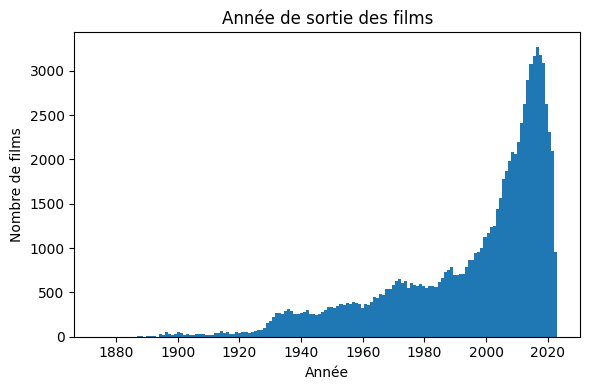

In [17]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))

movies_with_date["year"].plot(kind="hist", bins=150, ax=ax)
ax.set_title("Année de sortie des films")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()

On voit donc bien ici que la majorité des films du dataset sont sortis après 2000, il y a une surreprésentation des films qui sont sortis après la création de la base de données IMBd en 1990.

### Approche par notes des films

In [18]:
display(ratings_movies["rating"].describe())
display(ratings["rating"].value_counts().sort_index())

count    3.196504e+07
mean     3.540361e+00
std      1.058993e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

rating
0.5     525132
1.0     946675
1.5     531063
2.0    2028622
2.5    1685386
3.0    6054990
3.5    4290105
4.0    8367654
4.5    2974000
5.0    4596577
Name: count, dtype: int64

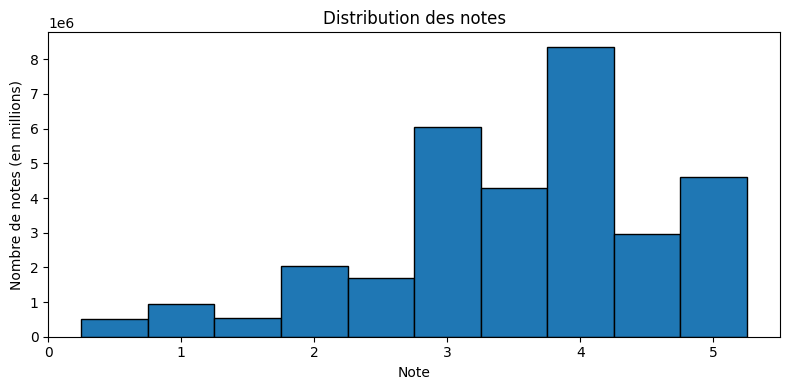

In [19]:
# Histogramme de toutes les notes
fig, ax = plt.subplots(figsize=(8, 4))
ratings_movies["rating"].plot(kind="hist", bins=[0.25 + 0.5 * i for i in range(11)], ax=ax, edgecolor="black")
ax.set_title("Distribution des notes")
ax.set_xlabel("Note")
ax.set_ylabel("Nombre de notes (en millions)")
plt.tight_layout()
plt.show()

Il y a 10 bins donc chaque rectangle est une note (0.5, 1, 1.5 ...). On peut donc voir les notes données par les utilisateurs. 4 est la note la plus donnée, suivie de 3 puis 5. On voit donc que l'on donne aux films surtout des bonnes notes, et que l'extrême positif (5) est 9 fois plus fréquent que l'extrême négatif (0,5) (4,5 millions à 0,5 millions de notes).

On observe que les notes entières sont systématiquements plus données que la note non entière supérieure et celle inférieure, on y voit peut-être là l'effet d'un biais psychologique qui fait préférer un chiffre entier à un non entier. On teste cette hypothèse sur les chiffres entiers.

In [20]:
# On regarde la part des notes non entières chaque année
demi_notes = (ratings["rating"] % 1 !=0).groupby(ratings["date"].dt.year).mean()
demi_notes

date
1995    0.000000
1996    0.000000
1997    0.000000
1998    0.000000
1999    0.000000
2000    0.000000
2001    0.000000
2002    0.000000
2003    0.290187
2004    0.443129
2005    0.442288
2006    0.434874
2007    0.435641
2008    0.437191
2009    0.434154
2010    0.435380
2011    0.432897
2012    0.426529
2013    0.419648
2014    0.415820
2015    0.390493
2016    0.396700
2017    0.400197
2018    0.395752
2019    0.399104
2020    0.406283
2021    0.407843
2022    0.415780
2023    0.412639
Name: rating, dtype: float64

On observe qu'avant 2003, il n'était probablement pas possible de mettre de demies notes, d'où le fait qu'il n'y en ait aucune. De 2004 à 2023, la part de demies notes est située entre 39% et 44%, donc s'il y a un biais qui fait préférer les notes entières aux demies notes, il est bien plus faible que ce que le premier graphique laissait penser. 

On voudrait préciser l'analyse et la centrer sur les notes données aux films. On regarde donc les notes moyennes par film, et on en fait un histogramme.

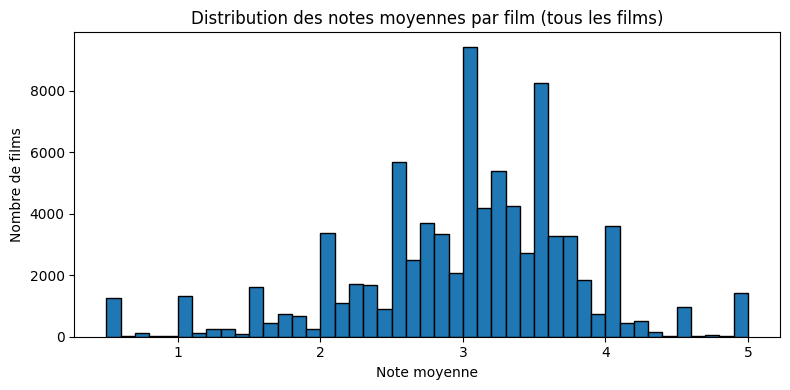

In [21]:
# Note moyenne et nombre de notes pour chaque film
notes_par_film = (
    ratings_movies
    .groupby("movieId")["rating"]
    .agg(note_moyenne="mean", nb_notes="count")
    .reset_index()
)

# 1. Histogramme des notes moyennes, tous les films
fig, ax = plt.subplots(figsize=(8, 4))
notes_par_film["note_moyenne"].plot(kind="hist", bins=45, ax=ax, edgecolor="black")
ax.set_title("Distribution des notes moyennes par film (tous les films)")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()


On remarque que cette représentation est assez éloignée d'une loi normale, on essaie de filtrer en ne gardant plus que les films qui ont un certain nombre de notes.

Films gardés : 15837


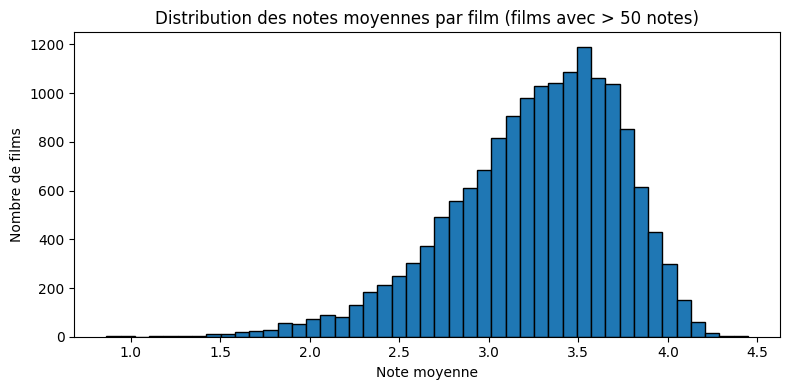

In [22]:
SEUIL = 50  # à modifier

# 2. Histogramme des notes moyennes, films avec plus de SEUIL notes
films_populaires = notes_par_film[notes_par_film["nb_notes"] > SEUIL]
print("Films gardés :", len(films_populaires))

fig, ax = plt.subplots(figsize=(8, 4))
films_populaires["note_moyenne"].plot(kind="hist", bins=45, ax=ax, edgecolor="black")
ax.set_title(f"Distribution des notes moyennes par film (films avec > {SEUIL} notes)")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()

Cette représentation se rapproche beaucoup d'une loi normale, de moyenne 3,4 environ, avec une asymétrie à gauche. 
La plupart des films sont bien notés, une moyenne en 3,5 à peu près, qui est supérieure à (5+0,5)/2 = 2,75 qui est le milieu de l'échelle de notes. Pourquoi est-ce qu'on note mieux que la moyenne, pourquoi les notes ne suivent pas une loi normale de moyenne 2,75 ?
Les notes plus basses sont rares, notamment parce qu'on ne regarde pas des films aléatoires, mais des films que l'on a envie de regarder, donc ils ont plus de chances de nous plaire (on peut toutefois être déçu bien sûr, cela n'empêche pas de mettre des mauvaises notes mais rend celles ci moins probables).

### Approche par genres des films

Intéressons nous désormais au genre des films. Créons un nouveau dataframe, qui duplique chaque ligne en autant de lignes que le film a de genres, pour rendre compte des différents genres des films.

In [23]:
# Une ligne par note et par genre
ratings_genres = ratings_movies.assign(genre=ratings_movies["genres"].str.split("|")).explode("genre")
display(ratings_genres[["userId", "movieId", "title", "rating", "genres", "genre"]].head(10))


,userId,movieId,title,rating,genres,genre
0,1,17,Sense and Sensibility,4.0,Drama|Romance,Drama
0,1,17,Sense and Sensibility,4.0,Drama|Romance,Romance
1,1,25,Leaving Las Vegas,1.0,Drama|Romance,Drama
1,1,25,Leaving Las Vegas,1.0,Drama|Romance,Romance
2,1,29,"City of Lost Children, The (Cité des enfants p...",2.0,Adventure|Drama|Fantasy|Mystery|Sci-Fi,Adventure
2,1,29,"City of Lost Children, The (Cité des enfants p...",2.0,Adventure|Drama|Fantasy|Mystery|Sci-Fi,Drama
2,1,29,"City of Lost Children, The (Cité des enfants p...",2.0,Adventure|Drama|Fantasy|Mystery|Sci-Fi,Fantasy
2,1,29,"City of Lost Children, The (Cité des enfants p...",2.0,Adventure|Drama|Fantasy|Mystery|Sci-Fi,Mystery
2,1,29,"City of Lost Children, The (Cité des enfants p...",2.0,Adventure|Drama|Fantasy|Mystery|Sci-Fi,Sci-Fi
3,1,30,Shanghai Triad (Yao a yao yao dao waipo qiao),5.0,Crime|Drama,Crime


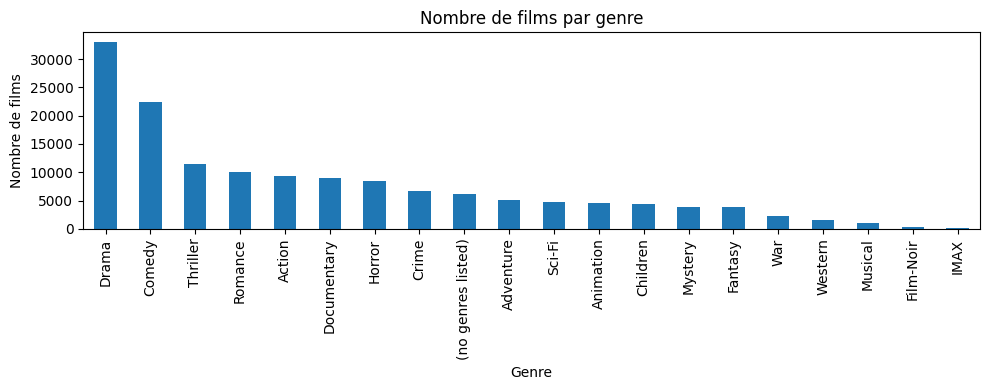

In [24]:
# Nombre de films par genre (chaque film compte dans tous ses genres)
films_par_genre = (
    ratings_genres
    .groupby("genre")["movieId"]
    .nunique()
    .sort_values(ascending=False)
)
films_par_genre.head()

# Graphique : nombre de films par genre
fig, ax = plt.subplots(figsize=(10, 4))
films_par_genre.plot(kind="bar", ax=ax)
ax.set_title("Nombre de films par genre")
ax.set_xlabel("Genre")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()


Certains genres sont surreprésentés, même si le classement dans un genre est partiellement arbitraire. Drama et comedy sont surreprésentés car on peut classifier la majorité des films dans une de ces catégories. Certaines films n'ont pas de catégorie (no genres listed), ou ont une catégorie qui a peu de sens (IMAX, qui signifie probablement spectaculaire, même si ce nom représente une technique plutôt qu'un genre cinématographique).

Représentons à présent les notes en fonction des genres.

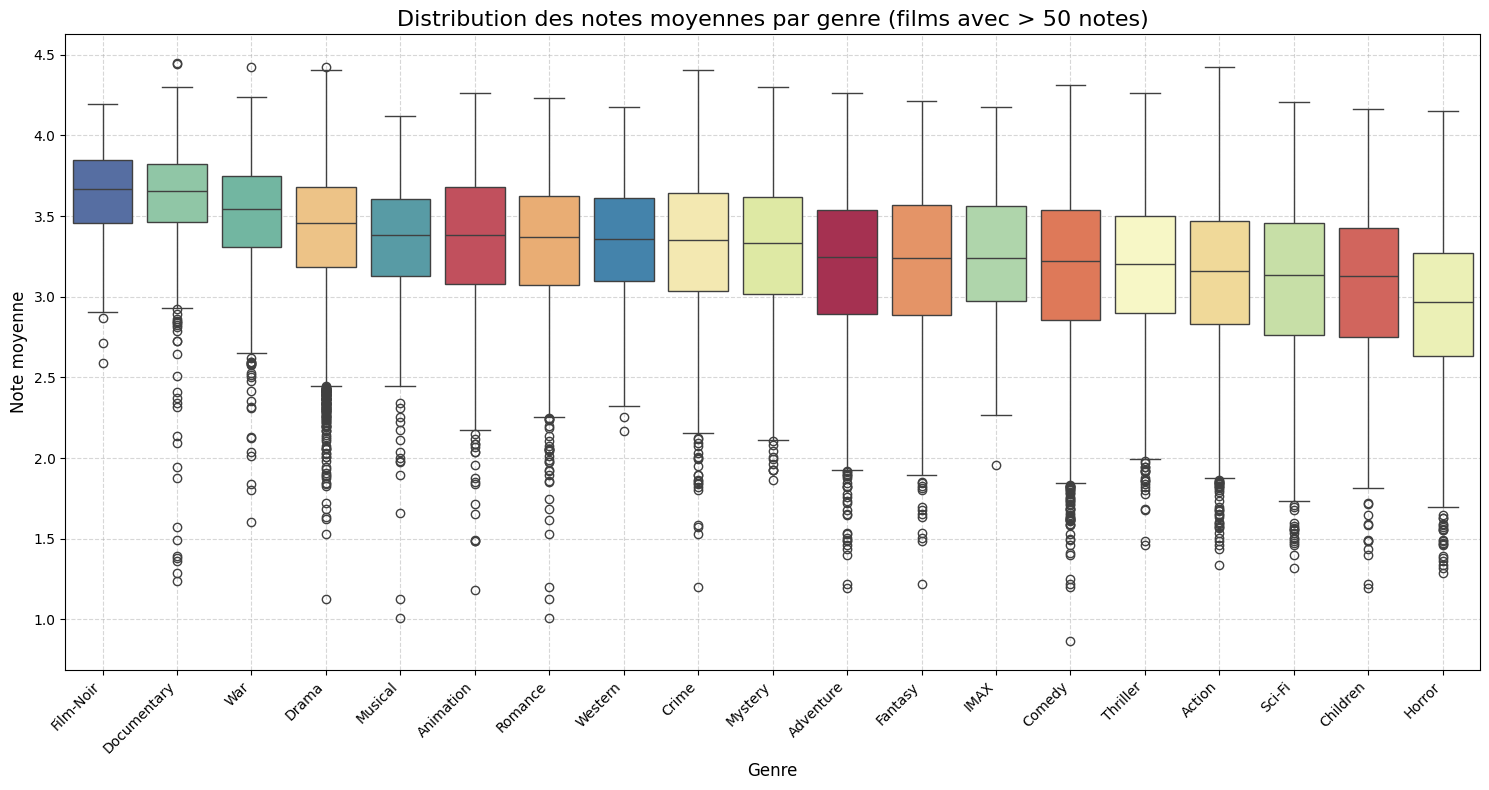

In [25]:
import seaborn as sns

SEUIL = 50  # à faire varier en fonction du nombre de notes chargées

# 1. Note moyenne et nombre de notes par film
notes_par_film = (
    ratings_movies
    .groupby("movieId")["rating"]
    .agg(note_moyenne="mean", nb_notes="count")
    .reset_index()
)

# 2. Garder les films populaires et récupérer leurs genres
films_populaires = notes_par_film[notes_par_film["nb_notes"] > SEUIL]
films_populaires = films_populaires.merge(movies[["movieId", "genres"]], on="movieId")

# 3. Une ligne par genre pour chaque film
films_populaires["genre"] = films_populaires["genres"].str.split("|")
genres_df = films_populaires.explode("genre")
genres_df = genres_df[genres_df["genre"] != "(no genres listed)"]

# 4. Ordre des genres selon la médiane des notes moyennes
ordre = (
    genres_df
    .groupby("genre")["note_moyenne"]
    .median()
    .sort_values(ascending=False)
    .index
)

# 5. Boxplot
plt.figure(figsize=(15, 8))
sns.boxplot(
    data=genres_df,
    x="genre",
    y="note_moyenne",
    order=ordre,
    hue="genre",
    palette="Spectral",
    legend=False,
)
plt.title(f"Distribution des notes moyennes par genre (films avec > {SEUIL} notes)", fontsize=16)
plt.xlabel("Genre", fontsize=12)
plt.ylabel("Note moyenne", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

On enlève certains films qui sont très peu notés qui induisent beaucoup de variance. On peut donc observer les médianes de notes moyennes des films qui appartiennent à chacun des genres. On voit donc qu'il y a une forte différence de notation en fonction du genre. Le genre "film noir" est le mieux noté, avec une note moyenne de 3,7 (probablement moins significative cependant parce qu'on a vu auparavant que le film noir était le deuxième genre le moins représenté), alors que le genre d'horreur est le moins bien noté à 3 en moyenne.

### Approche par utilisateurs



In [26]:
print("Nombre d'utilisateurs :", ratings_movies["userId"].nunique())

Nombre d'utilisateurs : 200948


Il y a 200948 utilisateurs différents. 

In [27]:
# Statistiques par utilisateur
stats_users = (
    ratings_movies
    .groupby("userId")["rating"]
    .agg(note_moyenne="mean", variance="var", nb_notes="count")
    .reset_index()
)
display(stats_users.head())
stats_users.describe()

,userId,note_moyenne,variance,nb_notes
0,1,3.531915,2.365046,141
1,2,4.269231,1.259427,52
2,3,3.588435,1.029797,147
3,4,2.629630,1.088319,27
4,5,3.272727,0.829545,33


,userId,note_moyenne,variance,nb_notes
count,200948.000000,200948.000000,200948.000000,200948.000000
mean,100474.500000,3.704384,0.910827,159.071193
std,58008.835284,0.486605,0.541026,281.501897
min,1.000000,0.500000,0.000000,18.000000
25%,50237.750000,3.415326,0.539147,36.000000
50%,100474.500000,3.725000,0.800000,73.000000
75%,150711.250000,4.025000,1.157143,167.000000
max,200948.000000,5.000000,5.328947,33229.000000


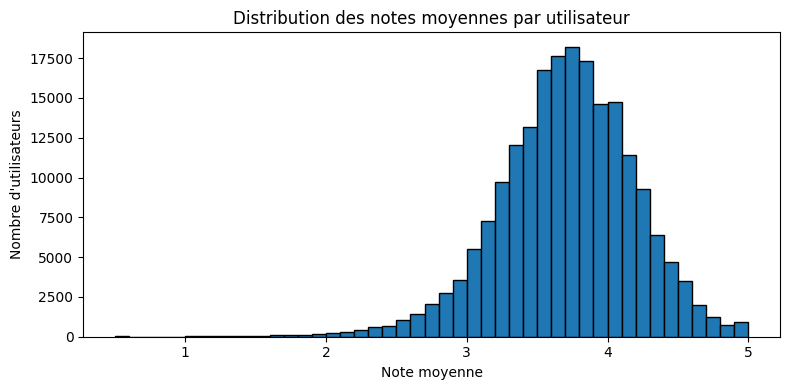

In [28]:
# Histogramme des notes moyennes par utilisateur
fig, ax = plt.subplots(figsize=(8, 4))
stats_users["note_moyenne"].plot(kind="hist", bins=45, ax=ax, edgecolor="black")
ax.set_title("Distribution des notes moyennes par utilisateur")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Nombre d'utilisateurs")
plt.tight_layout()
plt.show()

In [29]:
stats_users["note_moyenne"].describe()

count    200948.000000
mean          3.704384
std           0.486605
min           0.500000
25%           3.415326
50%           3.725000
75%           4.025000
max           5.000000
Name: note_moyenne, dtype: float64

La répartition des notes moyennes par utilisateur suit environ une loi normale de moyenne 3,7. La plupart des utilisateurs donnent des bonnes notes. 25% des utilisateurs donnent des notes supérieures à 4 en moyenne sont donc généreux.  

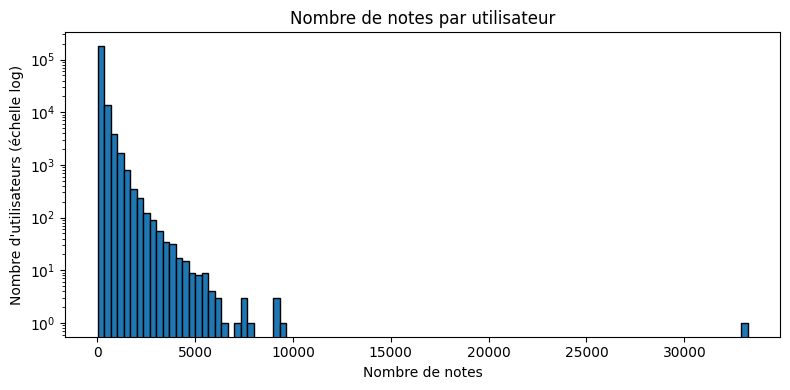

count    200948.000000
mean        159.071193
std         281.501897
min          18.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33229.000000
Name: nb_notes, dtype: float64

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
stats_users["nb_notes"].plot(kind="hist", bins=100, ax=ax, edgecolor="black")
ax.set_yscale("log")  # quelques gros utilisateurs écrasent le reste
ax.set_title("Nombre de notes par utilisateur")
ax.set_xlabel("Nombre de notes")
ax.set_ylabel("Nombre d'utilisateurs (échelle log)")
plt.tight_layout()
plt.show()

stats_users["nb_notes"].describe()

Les profils des utilisateurs sont donc très différents, certains sont très actifs (le maximum de notes étant de 33 000 !).

On peut essayer d'observer des profils d'utilisateurs en fonction de leur note moyenne et de leur variance. Le README du dataset indique qu'ils ont tous au moins 20 notes, donc on n'a pas besoin de filtrer les utilisateurs sur ce critère. Le minimum de 18 sur le describe précédent s'explique du fait qu'on a enlevé les films dont on ne connaissait pas la date. 

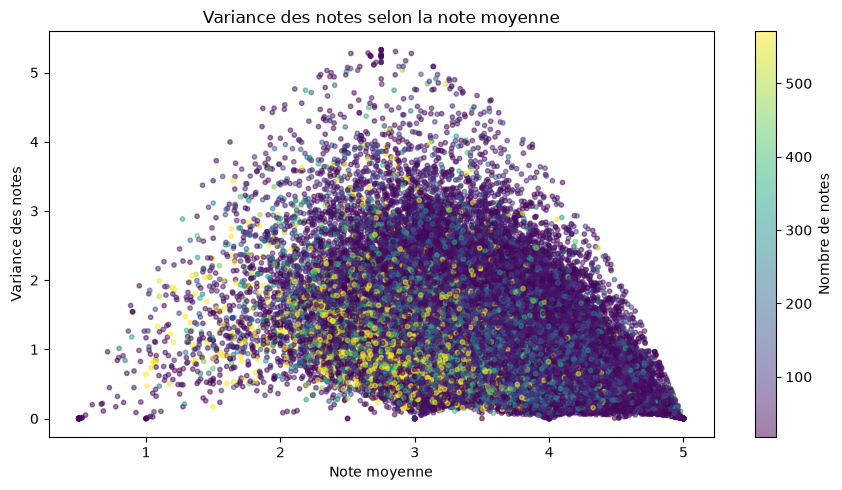

In [48]:
fig, ax = plt.subplots(figsize=(9, 5))
points = ax.scatter(
    stats_users["note_moyenne"],
    stats_users["variance"],
    c=stats_users["nb_notes"],
    cmap="viridis",
    vmax=stats_users["nb_notes"].quantile(0.95),  # évite qu'un seul gros utilisateur écrase les couleurs
    alpha=0.5,
    s=10,
)
fig.colorbar(points, ax=ax, label="Nombre de notes")
ax.set_title("Variance des notes selon la note moyenne")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Variance des notes")
plt.tight_layout()
plt.show()

A COMMENTER. 

### Approche sur les notes en fonction du temps, descriptive

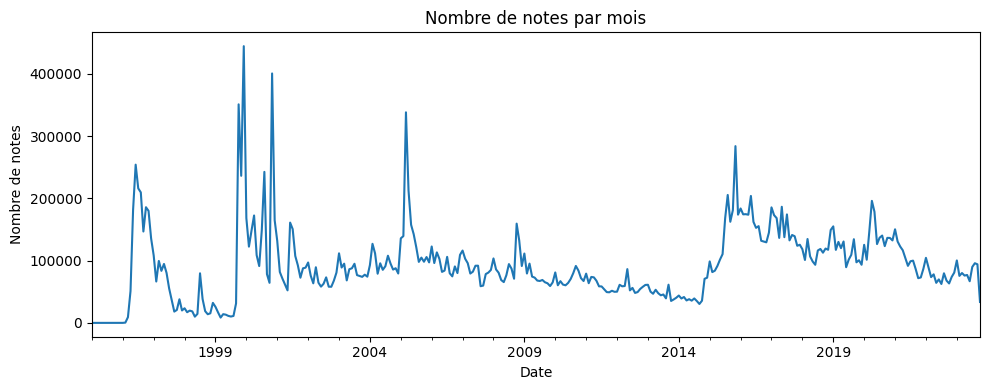

In [32]:
# Nombre de notes par mois
notes_par_mois = ratings_movies.groupby(ratings_movies["date"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(10, 4))
notes_par_mois.plot(ax=ax)
ax.set_title("Nombre de notes par mois")
ax.set_xlabel("Date")
ax.set_ylabel("Nombre de notes")
plt.tight_layout()
plt.show()

On observe donc des pics d'activité des utilisateurs au cours du temps, en 1996, au début des années 2000 puis qui se stabilise autour de 100 000 notes enregistrées par mois, puis il y a un regain d'activité vers 2016, puis l'activité décline lentement. 

# IV - Analyse de l'évolution des notes des films dans le temps

### A) Comment évolue la notation des utilisateurs dans le temps ?

,note_moyenne,nb_notes
anciennete,,
0,3.562482,27065120
1,3.437095,1321523
2,3.418746,855652
3,3.430314,625816
4,3.435322,449851
5,3.410186,332710
6,3.402215,242987
7,3.398269,183494
8,3.401733,137543


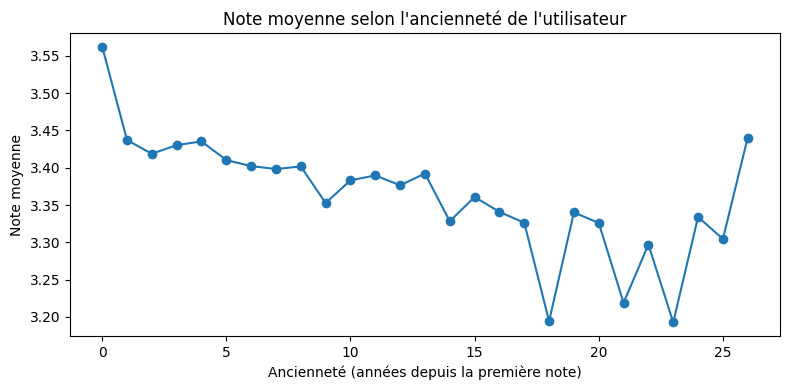

In [33]:
def ajouter_anciennete(df):
    """Ajoute l'ancienneté (en années entières) de chaque note par rapport à la première note de l'utilisateur."""
    df = df.copy()
    premiere_date = df.groupby("userId")["date"].transform("min")
    df["anciennete"] = (df["date"] - premiere_date).dt.days // 365
    return df


# On ne garde que les utilisateurs actifs
ids_actifs = users_actifs["userId"]
notes_actifs = ratings_movies[ratings_movies["userId"].isin(ids_actifs)]
notes_anciennete = ajouter_anciennete(notes_actifs)

# Note moyenne et nombre de notes selon l'ancienneté
par_anciennete = notes_anciennete.groupby("anciennete")["rating"].agg(note_moyenne="mean", nb_notes="count")
display(par_anciennete)

fig, ax = plt.subplots(figsize=(8, 4))
par_anciennete["note_moyenne"].plot(marker="o", ax=ax)
ax.set_title("Note moyenne selon l'ancienneté de l'utilisateur")
ax.set_xlabel("Ancienneté (années depuis la première note)")
ax.set_ylabel("Note moyenne")
plt.tight_layout()
plt.show()

On voit que 27 millions de notes sur 32 millions sont situées la première année donc on affine l'analyse sur la première année. A l'autre extrémité, on restreint l'analyse aux notes publiées moins de 15 ans après la première notation de l'utilisateur, car après 15 ans le graphique est moins significatif en raison d'un manque de notes. 

,note_moyenne,nb_notes,nb_utilisateurs
tranche,,,
1re semaine,3.586407,22460305,195506
reste du 1er mois,3.431318,1492085,38595
mois 2 à 6,3.459022,1995531,41913
mois 7 à 12,3.441697,1122283,25601
année 2,3.437002,1319364,22146
année 3,3.418687,854611,14778
année 4,3.429910,625111,10662
année 5,3.435540,449817,8038
année 6,3.410364,332407,6121


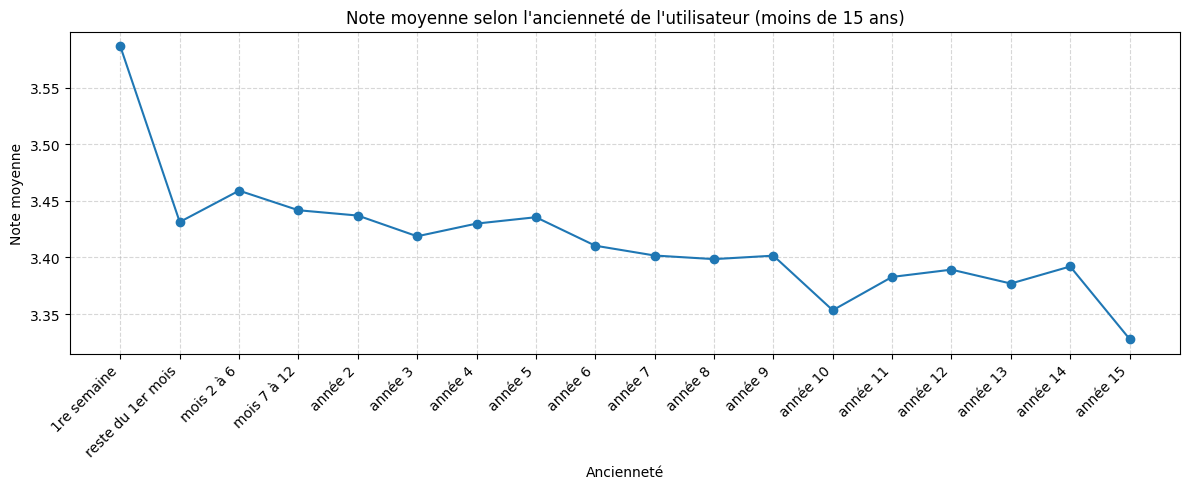

In [34]:
def ajouter_jours(df):
    """Ajoute le nombre de jours écoulés depuis la première note de l'utilisateur."""
    df = df.copy()
    premiere_date = df.groupby("userId")["date"].transform("min")
    df["jours"] = (df["date"] - premiere_date).dt.days
    return df


# Limites des tranches (en jours) et leurs noms
limites = [-1, 7, 30, 182, 365] + [365 * k for k in range(2, 16)]
noms = ["1re semaine", "reste du 1er mois", "mois 2 à 6", "mois 7 à 12"]
noms = noms + [f"année {k}" for k in range(2, 16)]

# Utilisateurs actifs (> 20 notes), ancienneté en jours
notes_actifs = ratings_movies[ratings_movies["userId"].isin(users_actifs["userId"])]
notes_jours = ajouter_jours(notes_actifs)

# Tranche de chaque note (les notes après 15 ans sont exclues)
notes_jours["tranche"] = pd.cut(notes_jours["jours"], bins=limites, labels=noms)

par_tranche = (
    notes_jours
    .groupby("tranche", observed=False)["rating"]
    .agg(note_moyenne="mean", nb_notes="count")
)
par_tranche["nb_utilisateurs"] = notes_jours.groupby("tranche", observed=False)["userId"].nunique()
display(par_tranche)

fig, ax = plt.subplots(figsize=(12, 5))
par_tranche["note_moyenne"].plot(marker="o", ax=ax)
ax.set_xticks(range(len(noms)))
ax.set_xticklabels(noms, rotation=45, ha="right")
ax.set_title("Note moyenne selon l'ancienneté de l'utilisateur (moins de 15 ans)")
ax.set_xlabel("Ancienneté")
ax.set_ylabel("Note moyenne")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

On observe donc que la note moyenne donnée diminue avec l'ancienneté de l'utilisateur. Ils enregistrent toujours la majorité de leurs notes dans la première semaine (22 millions sur 32 millions), et elles sont meilleures que celles enregistrées plus tard. C'est probablement car chaque utilisateur enregistre ses films préférés en premier quand il commence à utiliser la plateforme, et que les nombreux utilisateurs qui ne donneront pas de notes par la suite (195 506 utilisateurs la première semaine, il n'en reste plus que 38 595 qui enregistrent des notes dans la suite du mois) n'enregistrent probablement que leurs films préférés, et sont peut-être plus bienveillants dans leurs notes que des critiques expérimentés.
Le déclin de la note moyenne, qui se vérifie même si la pente est faible s'explique peut-être par une plus grande exigence envers les films lorsque l'utilisateur en a vu beaucoup, et aussi qu'il prend plus de risques avec les films qu'il regarde, autrement dit il regarde moins de films dont il sait qu'ils vont lui plaire. 

On peut aussi tester ces hypothèses en regardant la variance des notes données par les utilisateurs, et son évolution dans le temps.

,variance_moyenne,nb_utilisateurs
tranche,,
1re semaine,0.911552,194305
reste du 1er mois,0.764041,27072
mois 2 à 6,0.770609,33128
mois 7 à 12,0.744048,20569
année 2,0.745842,18725
année 3,0.719552,12689
année 4,0.688053,9008
année 5,0.662776,6851
année 6,0.647327,5215


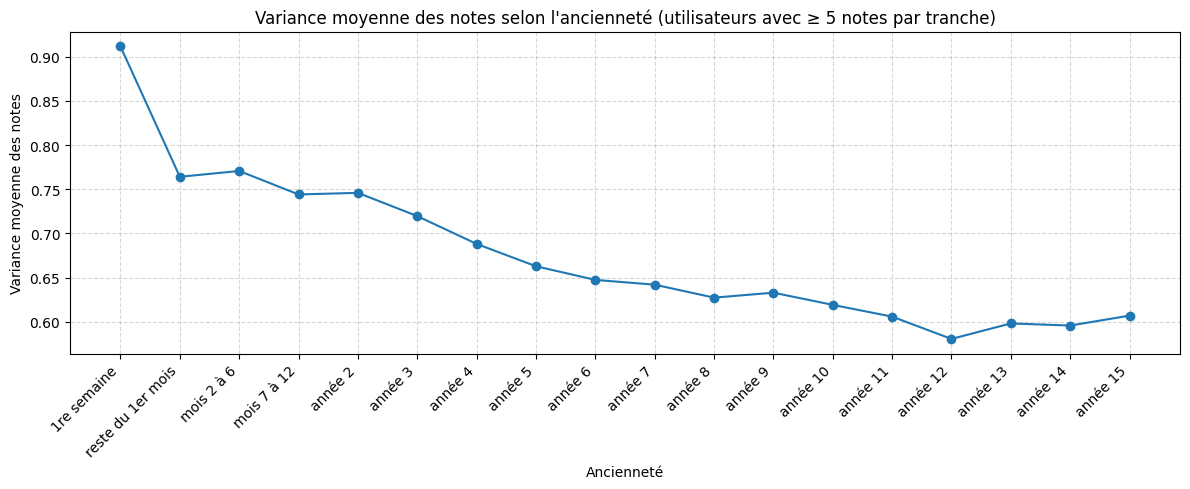

In [35]:
MIN_NOTES = 5  # nombre minimal de notes d'un utilisateur dans une tranche (à modifier)

# Variance des notes de chaque utilisateur dans chaque tranche
var_user_tranche = (
    notes_jours
    .groupby(["userId", "tranche"], observed=True)["rating"]
    .agg(variance="var", nb_notes="count")
    .reset_index()
)
var_user_tranche = var_user_tranche[var_user_tranche["nb_notes"] >= MIN_NOTES]

# Moyenne des variances par tranche
par_tranche_var = var_user_tranche.groupby("tranche", observed=False).agg(
    variance_moyenne=("variance", "mean"),
    nb_utilisateurs=("userId", "nunique"),
)
display(par_tranche_var)

fig, ax = plt.subplots(figsize=(12, 5))
par_tranche_var["variance_moyenne"].plot(marker="o", ax=ax)
ax.set_xticks(range(len(noms)))
ax.set_xticklabels(noms, rotation=45, ha="right")
ax.set_title(f"Variance moyenne des notes selon l'ancienneté (utilisateurs avec ≥ {MIN_NOTES} notes par tranche)")
ax.set_xlabel("Ancienneté")
ax.set_ylabel("Variance moyenne des notes")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

On est surpris car on observe une baisse de la variance des notes, alors qu'on se serait attendu à ce qu'elle augmente autrement dit que l'utilisateur habitué mette plus de notes extrêmes. On peut omettre les années supérieures à la dixième année de l'analyse étant donné que moins de 2000 utilisateurs sont concernés, elles sont moins significatives.
Comment expliquer ce paradoxe ?

### B) Comment évolue la notation des films dans le temps ?

Après l'ancienneté des utilisateurs, on regarde celle des films : leurs notes
changent-elles avec le temps, et observe-t-on les mêmes évolutions pour tous les films ? Par quels critères/ facteurs peut-on prédire ces évolutions ? 


In [56]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

#import importlib
#import fonction_analyse_film
#importlib.reload(fonction_analyse_film)

from fonction_analyse_film import (
    resumer_notes_par_anciennete, tracer_notes_par_anciennete,
    construire_table_periodes, tracer_trajectoire, tracer_variations)

#### Les notes selon l'ancienneté du film

L'ancienneté est l'année de notation moins l'année de sortie : zéro correspond
à la même année civile. On écarte les anciennetés négatives et les dates manquantes.

On compare deux moyennes : l'une où chaque note compte autant, l'autre où chaque
film compte autant. La première donne davantage de poids aux films les plus notés.
On affiche aussi les effectifs et on masque les moyennes avec moins de 1 000 notes.

Notes utilisées : 31,964,024


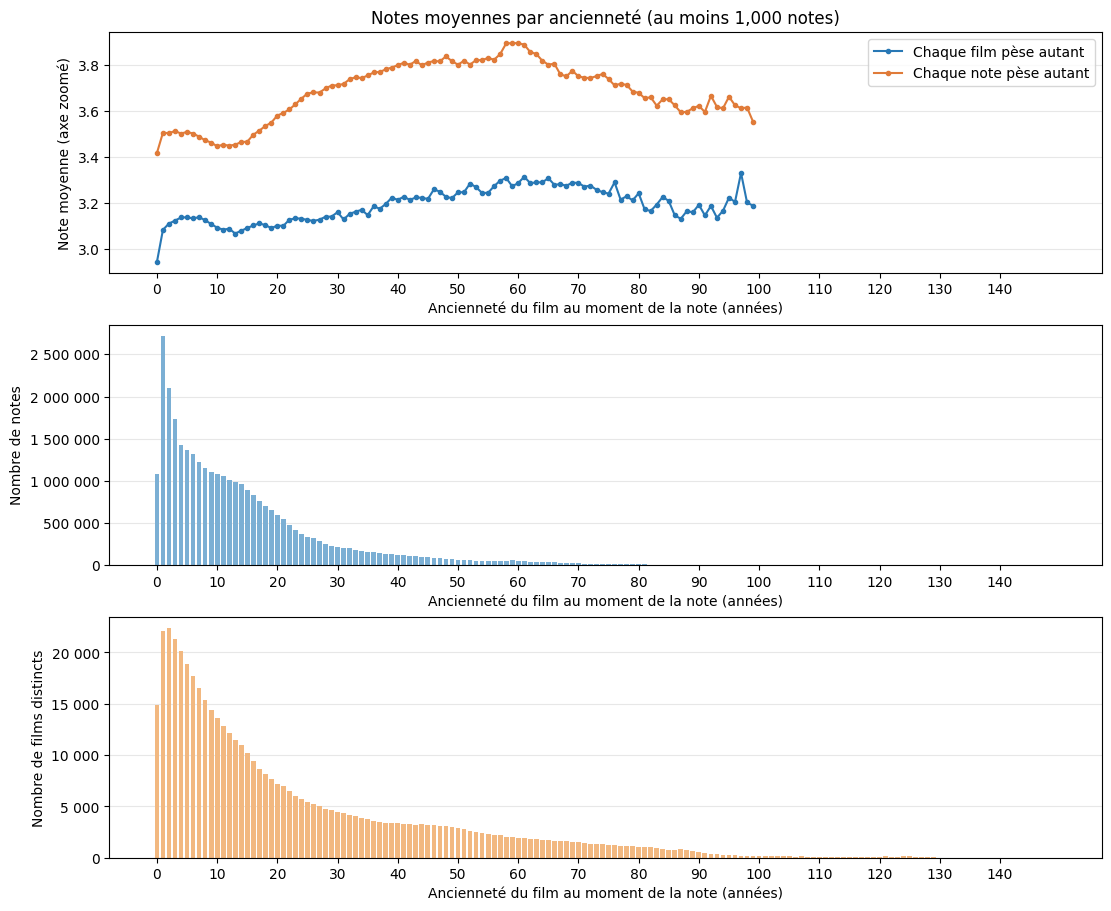

In [45]:
# On agrège une seule fois les notes : la suite réutilise cette petite table.
par_film = resumer_notes_par_anciennete(ratings_movies)
print(f"Notes utilisées : {par_film['nombre_notes'].sum():,}")
tracer_notes_par_anciennete(par_film, seuil_notes=1000)

Les notes remontent globalement après les premières années, surtout lorsque
chaque note compte autant. Mais les films notés à deux ans ne sont pas les mêmes
que ceux encore notés à soixante ans. On cherche donc si une remontée apparaît
aussi lorsqu'on suit **les mêmes films**.

#### 1. Retrouve-t-on une baisse puis une remontée chez les mêmes films ?

On compare trois périodes : **0–2 ans, 5–9 ans et 15–19 ans**. Pour suivre les
mêmes films, il faut que ces trois périodes soient couvertes par les données,
qui vont de janvier 1995 à octobre 2023. On retient donc les sorties de
**1995 à 2003** :

- avant 1995, il manque tout ou partie des notes des premières années ;
- pour un film de 2003, le suivi à 19 ans finit en 2022, une année complète.
  Un film de 2004 atteindrait 19 ans en 2023, qui n'est couverte que jusqu'en octobre.

Cette restriction permet de couvrir les trois périodes pour une même cohorte.
On garde les films avec **au moins 10 notes dans chacune**.

On calcule la moyenne de toutes les notes de chaque film sur chaque période,
puis la moyenne entre films : chaque film retenu compte autant (méthode de la double moyenne pour éviter les effets de popularité déjà utilisée ci-dessu). Pour retrouver
la moyenne d'une période, les moyennes annuelles sont pondérées par leurs
nombres de notes.

Films retenus : 2,059 sur 9,409


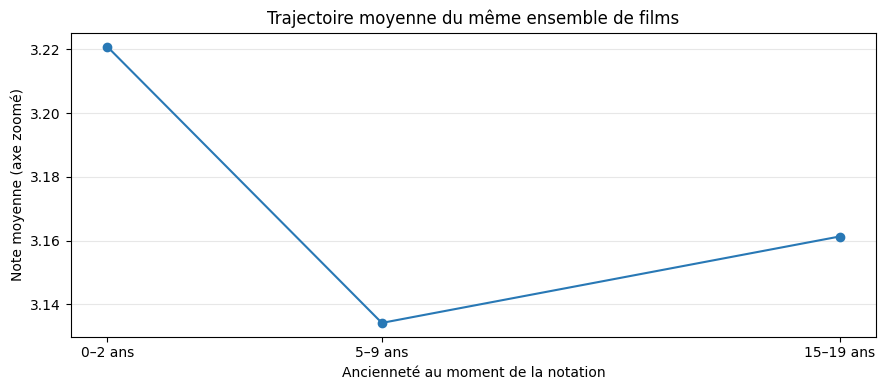

,periode,note_moyenne,nombre_films,nombre_notes
0,0–2 ans,3.221,2059,2589016
1,5–9 ans,3.134,2059,2242820
2,15–19 ans,3.161,2059,1682781


In [46]:
annee_min = 1995
annee_max = 2003
minimum_notes = 10
periodes = [("debut", 0, 2), ("intermediaire", 5, 9), ("tardif", 15, 19)]

table_trajectoires = construire_table_periodes(
    par_film, movies_with_date, periodes, annee_min, annee_max
)
colonnes_effectifs = [f"nb_notes_{nom}" for nom, debut, fin in periodes]
assez_de_notes = (table_trajectoires[colonnes_effectifs] >= minimum_notes).all(axis=1)
comparaison_films = table_trajectoires.loc[assez_de_notes].copy()
print(f"Films retenus : {len(comparaison_films):,} sur {len(table_trajectoires):,}")

resume_trajectoire = tracer_trajectoire(comparaison_films, periodes)
display(resume_trajectoire.round(3))

On conserve **2 059 films sur 9 409**. Leur moyenne passe de **3,221 à 3,134,
puis à 3,161** : une baisse de 0,087 point, suivie d'une reprise de 0,027 point.
La reprise est donc partielle, et la moyenne finale reste sous celle du début.

Cette fois, les films sont les mêmes aux trois points, mais les publics peuvent
changer. Ces moyennes de périodes ne décrivent pas toutes les fluctuations ni
le parcours jusqu'à soixante ans des films de la courbe précédente.

#### 2. La moyenne cache-t-elle des trajectoires différentes ?

On distingue pour chaque film :

- la variation initiale B : moyenne à 5–9 ans moins moyenne à 0–2 ans ;
- la reprise R : moyenne à 15–19 ans moins moyenne à 5–9 ans.

Une baisse puis une remontée correspond à B négatif et R positif. On compare
les effectifs et les amplitudes pour voir si la trajectoire moyenne est répandue.

,nombre_films,variation_initiale_mediane,reprise_mediane,part_films_pct
profil,,,,
Baisse puis remontée,797,-0.206,0.164,38.708
Baisse sur les deux phases,559,-0.146,-0.121,27.149
Hausse puis baisse,381,0.136,-0.143,18.504
Hausse sur les deux phases,319,0.117,0.111,15.493
Variation nulle sur une phase,3,0.096,0.000,0.146


Reprise positive : 54.2% ; reprise médiane : +0.023 point


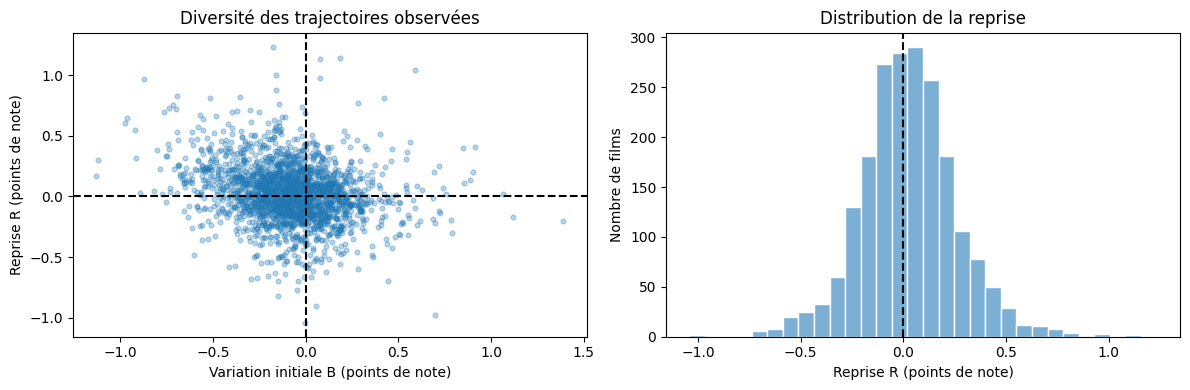

In [60]:
comparaison_films["variation_initiale"] = (
    comparaison_films["note_intermediaire"] - comparaison_films["note_debut"]
)
comparaison_films["reprise"] = (
    comparaison_films["note_tardif"] - comparaison_films["note_intermediaire"]
)
B = comparaison_films["variation_initiale"]
R = comparaison_films["reprise"]

# Ces profils décrivent les signes observés, sans seuil de significativité.
comparaison_films["profil"] = "Variation nulle sur une phase"
comparaison_films.loc[(B < 0) & (R > 0), "profil"] = "Baisse puis remontée"
comparaison_films.loc[(B < 0) & (R < 0), "profil"] = "Baisse sur les deux phases"
comparaison_films.loc[(B > 0) & (R > 0), "profil"] = "Hausse sur les deux phases"
comparaison_films.loc[(B > 0) & (R < 0), "profil"] = "Hausse puis baisse"

resume_profils = comparaison_films.groupby("profil").agg(
    nombre_films=("movieId", "count"),
    variation_initiale_mediane=("variation_initiale", "median"),
    reprise_mediane=("reprise", "median")
).sort_values("nombre_films", ascending=False)
resume_profils["part_films_pct"] = 100 * resume_profils["nombre_films"] / len(comparaison_films)
display(resume_profils.round(3))
print(f"Reprise positive : {(R > 0).mean():.1%} ; reprise médiane : {R.median():+.3f} point")
tracer_variations(comparaison_films)

**797 films, soit 38,7 %, baissent puis remontent** : cette trajectoire ne concerne
donc pas tous les films. Au total, **54,2 %** ont une reprise positive, mais la
reprise médiane reste faible : **+0,023 point**.

B et R partagent la même moyenne intermédiaire, avec des signes opposés : une
valeur momentanément basse peut créer une apparence de baisse puis remontée.
Les profils restent descriptifs, surtout pour les petites variations.

#### Quelle est l'ampleur des variations tardives aussi appelé reprise ?

La hausse moyenne est faible. On regarde donc la dispersion et les amplitudes
avant de chercher à les expliquer. Le seuil de 0,25 point est un repère
descriptif ; les deux exemples ont au moins 100 notes dans chaque période.

In [61]:
# Une faible moyenne peut cacher des hausses et des baisses qui se compensent.
resume_variations = R.agg(["mean", "median", "std", "var", "min", "max"])
resume_variations.index = [
    "Moyenne (points)", "Médiane (points)", "Écart-type (points)",
    "Variance (points²)", "Minimum (points)", "Maximum (points)"
]
display(resume_variations.round(3))
print(
    f"Au moins 0,25 point : {(R >= 0.25).sum()} hausses ({(R >= 0.25).mean():.1%}) ; "
    f"{(R <= -0.25).sum()} baisses ({(R <= -0.25).mean():.1%})"
)

# Deux exemples parmi les films ayant au moins 100 notes dans chaque période.
films_documentes = comparaison_films.loc[
    (comparaison_films[colonnes_effectifs] >= 100).all(axis=1)
].sort_values("reprise")
display(films_documentes.iloc[[0, -1]][[
    "title", "note_intermediaire", "note_tardif", "reprise",
    "nb_notes_intermediaire", "nb_notes_tardif"
]].round(3))

Moyenne (points)       0.027
Médiane (points)       0.023
Écart-type (points)    0.243
Variance (points²)     0.059
Minimum (points)      -1.042
Maximum (points)       1.234
Name: reprise, dtype: float64

Au moins 0,25 point : 301 hausses (14.6%) ; 200 baisses (9.7%)


,title,note_intermediaire,note_tardif,reprise,nb_notes_intermediaire,nb_notes_tardif
345,Wallace & Gromit: The Best of Aardman Animation,4.195,3.526,-0.670,2309.0,978.0
1469,Pokémon: The First Movie,1.760,2.994,1.234,418.0,309.0


La moyenne est de **+0,027 point**, mais l'écart-type atteint **0,243 point**
(variance : **0,059 point²**). **301 films (14,6 %) gagnent au moins 0,25 point**
et **200 (9,7 %) perdent au moins autant**. Parmi les films suffisamment notés,
Pokémon: The First Movie gagne **1,234 point**, tandis que Wallace & Gromit:
The Best of Aardman Animation perd **0,670 point**.

On observe donc des hausses et des baisses marquées pour certains films tardivement (c'est à dire entre la note moyenne intermédiaire et la note moyenne tardive),
ce qui motive l'étude de leurs différences.
C'est cet effet tardif qui nous a le plus intéressé: il n'est pas forcément des plus intuitifs mais existe bien. Il pourrait rendre compte d'un effet de bonification tardif avec l'âge qui pourrait ressembler à un effet "le film devient un classique". Est ce le cas ? La suite tente d'y répondre.